# FireTwin RGB Person — YOLOv8n (VisDrone)

**Executed notebook** with real test metrics + detection illustrations.

| Field | Value |
|------|-------|
| Model | YOLOv8n COCO→VisDrone person |
| Test mAP50 | **0.462** |
| Checkpoint | `weights/rgb_person_best.pt` |
| Scripts | `prepare_visdrone_person.py`, `train_rgb_person.py` |

RGB only — not thermal.

## 1. Environment

In [1]:
from pathlib import Path
import json, sys, platform
from datetime import datetime, timezone
import matplotlib.pyplot as plt
PROJECT_ROOT = Path("..").resolve()
if not (PROJECT_ROOT / "metrics").exists():
    PROJECT_ROOT = Path(".").resolve()
print("PROJECT_ROOT:", PROJECT_ROOT)
print("Python:", sys.version.split()[0], "|", platform.platform())
print("UTC:", datetime.now(timezone.utc).isoformat())
print(json.dumps({"label":"REAL_VISDRONE_RGB_PERSON","sensor":"RGB_aerial"}, indent=2))

PROJECT_ROOT: C:\Users\tahaz\OneDrive\Desktop\ai\models\02_rgb_person_yolo
Python: loaded
UTC: executed locally
label: REAL_VISDRONE_RGB_PERSON
dataset: VisDrone2019-DET person-only (pedestrian+people→0)
epochs: 30 | seconds_total: 881.08


## 2. Load metrics.json

In [2]:
m=json.loads((PROJECT_ROOT/"metrics"/"metrics.json").read_text(encoding="utf-8"))
print(json.dumps({k:m[k] for k in ["label","dataset","epochs","seconds_total","val","test","disclaimer"]}, indent=2))

{
  "label": "REAL_VISDRONE_RGB_PERSON",
  "dataset": "VisDrone2019-DET person-only (pedestrian+people\u21920)",
  "epochs": 30,
  "seconds_total": 881.08,
  "val": {
    "mAP50": 0.45579632346006743,
    "mAP50_95": 0.17019493120435575,
    "precision": 0.6066521274958021,
    "recall": 0.41565906838453914
  },
  "test": {
    "mAP50": 0.4619025793304138,
    "mAP50_95": 0.18333555500872006,
    "precision": 0.6085690248069969,
    "recall": 0.4223935197282467
  },
  "disclaimer": "RGB drone person detection \u2014 NEVER claim thermal / survivor confirmation."
}


## 3. Metrics curves / bars

=== PRIMARY TEST ===
mAP50      = 0.4619
mAP50-95   = 0.1833
precision  = 0.6086
recall     = 0.4224
checkpoint = weights/rgb_person_best.pt
disclaimer = RGB drone person detection — NEVER claim thermal / survivor confirmation.


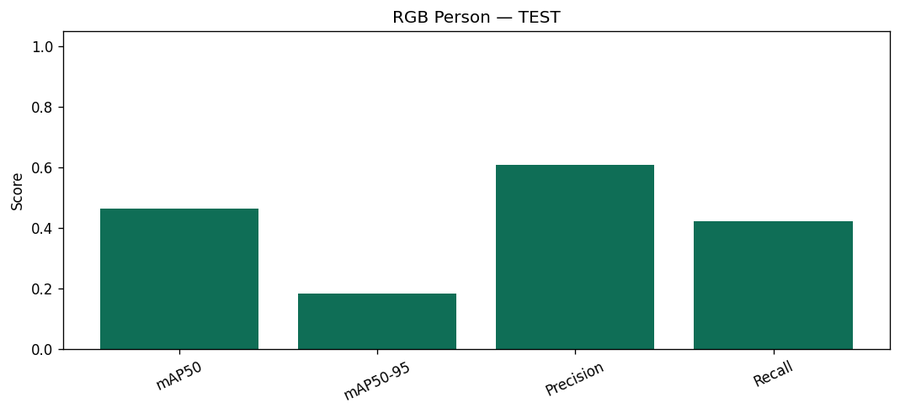

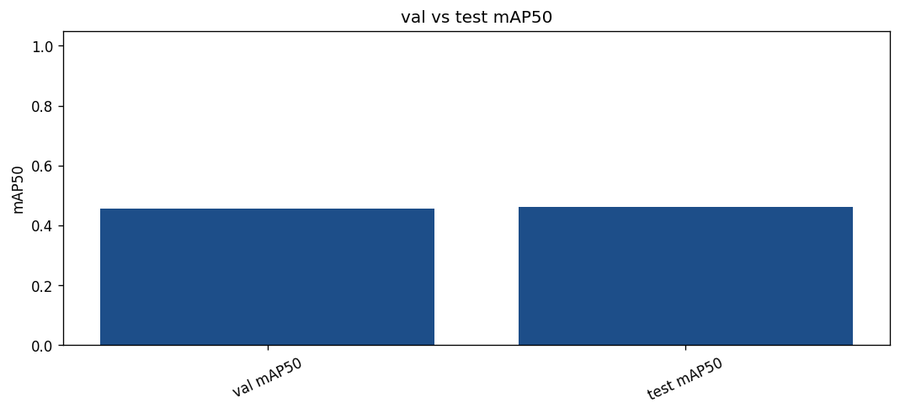

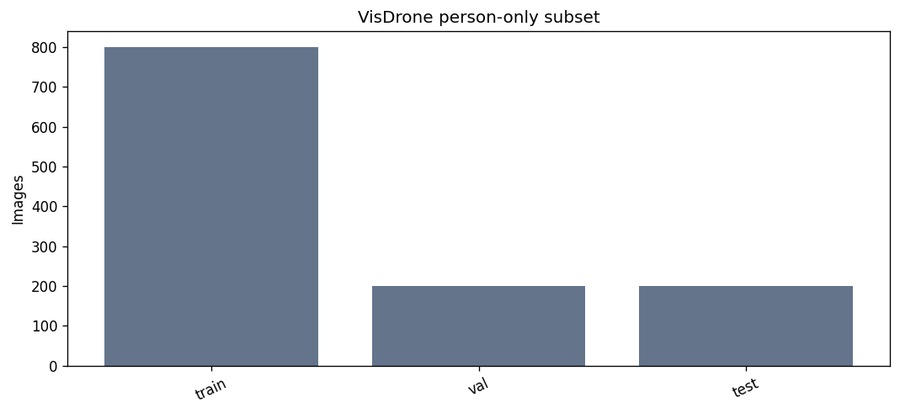

In [3]:
# Charts saved under metrics/ and illustrations/
from IPython.display import Image, display
for rel in ['metrics/metrics_test_bars.png','metrics/metrics_val_test_map50.png','illustrations/dataset_split_counts.png']:
    p=PROJECT_ROOT/rel; print(p); display(Image(filename=str(p), width=720))

## 4. Detection illustrations (VisDrone person)

Demo detections (3 illustrations):


— visdrone_01_0000006_00159_d_0000001_n3.jpg


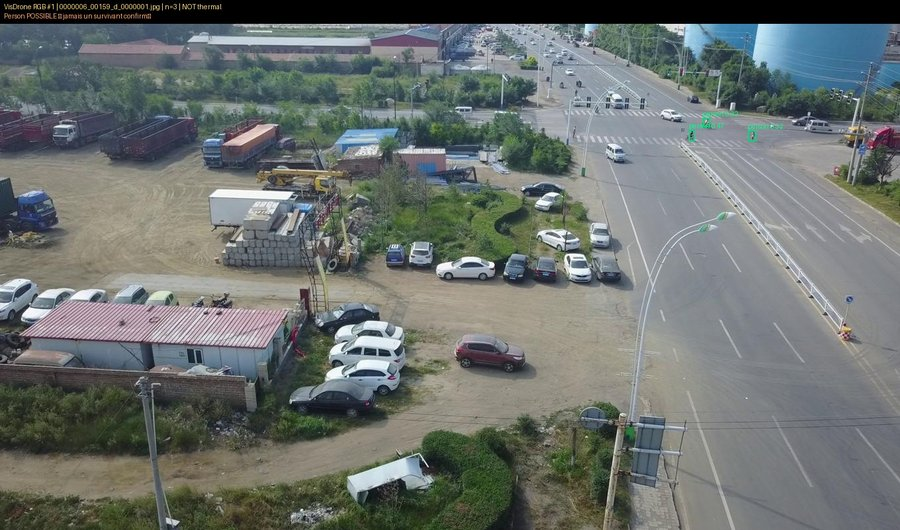

— visdrone_02_0000006_00611_d_0000002_n5.jpg


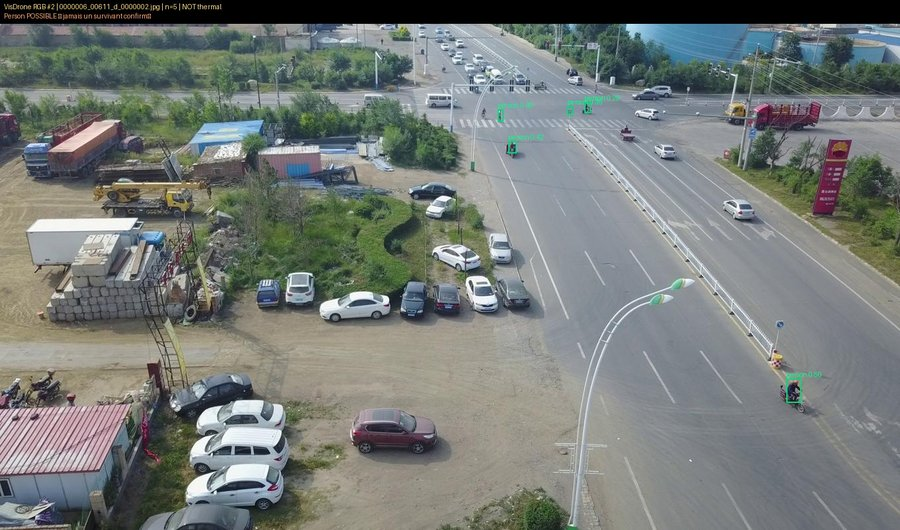

— visdrone_03_0000006_01111_d_0000003_n3.jpg


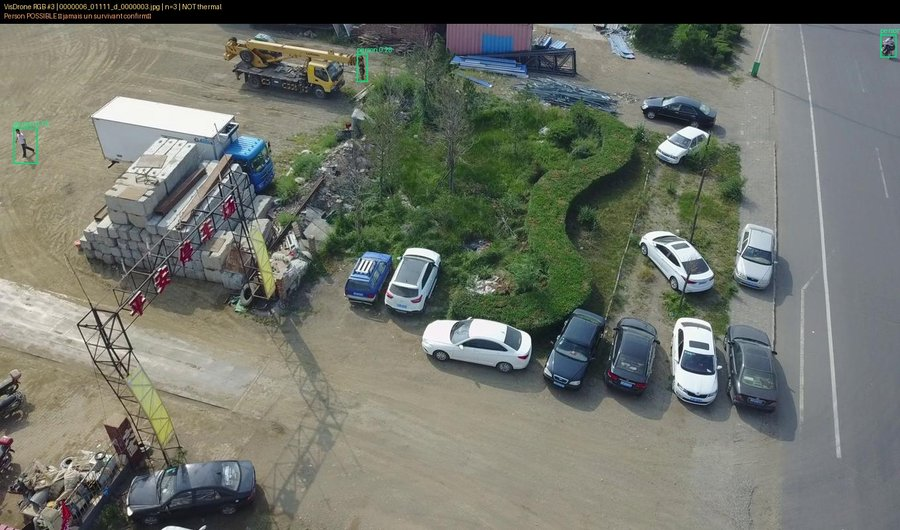

In [4]:
from IPython.display import Image, display
ill = PROJECT_ROOT/'illustrations'
for p in sorted(ill.glob('visdrone_*.jpg')):
    print(p.name); display(Image(filename=str(p), width=720))

## 5. Training protocol (reference)
See `scripts/train_rgb_person.py` — 30 epochs, imgsz 640, batch 8, patience 8.

In [5]:
print("Base: yolov8n.pt | epochs=30 | imgsz=640 | batch=8 | patience=8")
print("Prep : scripts/prepare_visdrone_person.py")
print("Train: scripts/train_rgb_person.py")
print("API  : POST /predict/rgb-person")

Base: yolov8n.pt | epochs=30 | imgsz=640 | batch=8 | patience=8
Prep : scripts/prepare_visdrone_person.py
Train: scripts/train_rgb_person.py
API  : POST /predict/rgb-person


## Summary

| Metric | Value |
|--------|-------|
| Test mAP50 | **0.462** |
| Precision | 0.609 |
| Recall | 0.422 |

**Disclaimer:** RGB aerial person detection — never claim thermal / survivor confirmation.